
# COMP8410 — Week 3: Identity Preservation and Controlled Image Editing

## Scenario
Skincare and cosmetics product-image editing.

## Objective
Compare image-editing approaches that change a requested product attribute while preserving the product's identity and scene composition.

### Models
1. FLUX.1 Kontext Dev — instruction-based image editing baseline.
2. Personalize Anything (AAAI 2026) — training-free personalization and controlled editing research method.

### Evaluation
- Edit instruction success
- Product identity preservation
- Composition preservation
- Visual quality
- Runtime
- Peak GPU memory

### Hardware
Google Colab GPU, preferably NVIDIA A100.

### References
- Personalize Anything paper: https://ojs.aaai.org/index.php/AAAI/article/view/37394
- Official implementation: https://github.com/fenghora/personalize-anything
- FLUX.1 Kontext Dev: https://huggingface.co/black-forest-labs/FLUX.1-Kontext-dev

Published claims must be distinguished from results measured in this experiment.


In [1]:
import os
import sys
import json
import time
import subprocess
from pathlib import Path

import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "Enable a GPU runtime in Colab: "
        "Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

gpu_memory_gib = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
)
print(f"Total GPU memory: {gpu_memory_gib:.2f} GiB")

WORK_DIR = Path("/content/comp8410_week3")
INPUT_DIR = WORK_DIR / "inputs"
OUTPUT_DIR = WORK_DIR / "outputs"

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Total GPU memory: 94.97 GiB


In [2]:
%pip -q install --upgrade diffusers transformers accelerate safetensors sentencepiece pillow pandas matplotlib huggingface_hub


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.



## Experimental design

Input: a skincare or cosmetics product photograph.

Task: change only one product attribute, such as the colour of a serum-bottle label.

Preserve:
- Bottle silhouette and proportions
- Cap and distinctive product details
- Label position and layout
- Background and composition
- Lighting and shadows

Use the same input image and edit instruction for both methods wherever their interfaces permit.

This is an end-to-end system comparison, not a controlled ablation of a single algorithmic component.


Saving Capture.JPG to Capture (1).JPG
Input image: /content/comp8410_week3/inputs/Capture (1).JPG
Image dimensions: (768, 721)


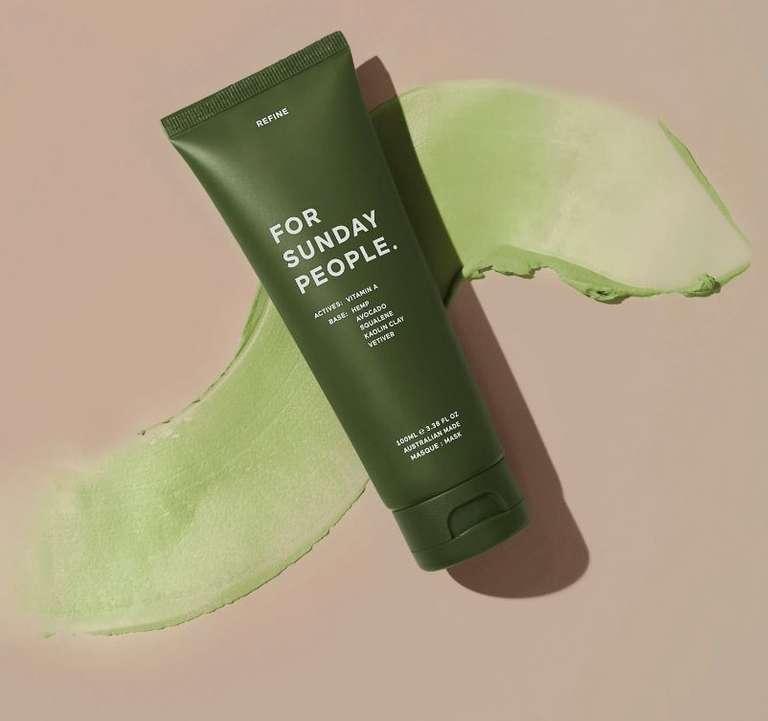

In [19]:

from google.colab import files
from PIL import Image
from IPython.display import display

uploaded = files.upload()

if not uploaded:
    raise ValueError("Upload a skincare or cosmetics product image.")

filename = next(iter(uploaded))
input_path = INPUT_DIR / filename
input_path.write_bytes(uploaded[filename])

image = Image.open(input_path).convert("RGB")
image.thumbnail((768, 768), Image.Resampling.LANCZOS)

print("Input image:", input_path)
print("Image dimensions:", image.size)

display(image)


In [4]:

SEED = 42

EDIT_PROMPT = (
    "Change only the label colour of the serum bottle to muted sage green. "
    "Preserve the exact bottle silhouette, cap, proportions, label placement, "
    "text layout, lighting, shadows, camera angle, background and composition. "
    "Keep the result photorealistic as premium skincare product photography."
)

print("Seed:", SEED)
print("Prompt:", EDIT_PROMPT)


Seed: 42
Prompt: Change only the label colour of the serum bottle to muted sage green. Preserve the exact bottle silhouette, cap, proportions, label placement, text layout, lighting, shadows, camera angle, background and composition. Keep the result photorealistic as premium skincare product photography.



## Model 1: FLUX.1 Kontext Dev

Purpose: provide a runnable instruction-based image-editing baseline.

The model receives the original image and a natural-language editing instruction.

We record:
- Inference time
- Peak allocated GPU memory
- Output image
- Subjective evaluation scores

Model access may require a Hugging Face account and acceptance of the model's terms.


In [5]:
!pip install --upgrade --no-cache-dir torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 87.7 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [6]:
#!pip install --upgrade --force-reinstall git+https://github.com/huggingface/diffusers.git

In [7]:

# If the repository requires authentication, uncomment:
#
from huggingface_hub import login

login()
#
# Enter credentials privately. Never publish an access token in your notebook.

from diffusers import FluxKontextPipeline

MODEL_ID = "black-forest-labs/FLUX.1-Kontext-dev"

dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

pipe = FluxKontextPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
)

pipe = pipe.to("cuda")
pipe.set_progress_bar_config(disable=False)

print("Loaded:", MODEL_ID)
print("Dtype:", dtype)


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Loaded: black-forest-labs/FLUX.1-Kontext-dev
Dtype: torch.bfloat16


  0%|          | 0/28 [00:00<?, ?it/s]

Runtime: 20.34 seconds
Peak allocated GPU memory: 33.83 GiB
Output: /content/comp8410_week3/outputs/flux_kontext_edit.png


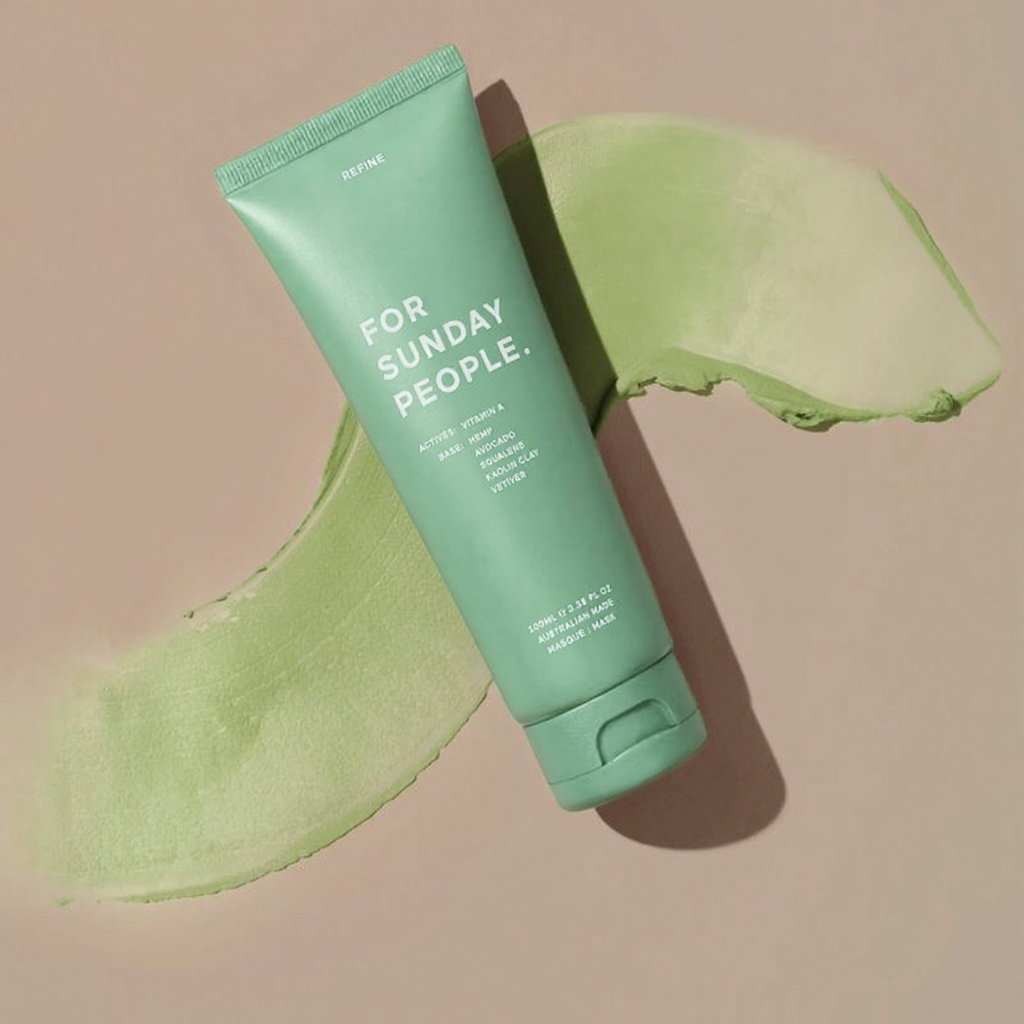

In [8]:

generator = torch.Generator(device="cuda").manual_seed(SEED)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

flux_output = pipe(
    image=image,
    prompt=EDIT_PROMPT,
    guidance_scale=2.5,
    num_inference_steps=28,
    generator=generator,
).images[0]

flux_runtime = time.perf_counter() - start_time

flux_peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

flux_output_path = OUTPUT_DIR / "flux_kontext_edit.png"
flux_output.save(flux_output_path)

print(f"Runtime: {flux_runtime:.2f} seconds")
print(f"Peak allocated GPU memory: {flux_peak_memory:.2f} GiB")
print("Output:", flux_output_path)

display(flux_output)



## Model 2: Personalize Anything (AAAI 2026)

Official repository:
https://github.com/fenghora/personalize-anything

This research implementation is intended for training-free personalization and controlled editing.

Do not assume it exposes the same API as FLUX.1 Kontext. Its upstream notebook, checkpoints, dependencies, and configuration must be followed.

The next cells clone the official implementation and inspect its setup instructions. The actual Personalize Anything inference must be run using the upstream workflow.


In [9]:

REPO_URL = "https://github.com/fenghora/personalize-anything.git"
REPO_DIR = Path("/content/personalize-anything")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True,
    )

print("Repository cloned:", REPO_DIR)

for path in sorted(REPO_DIR.iterdir()):
    print(path.name)


Repository cloned: /content/personalize-anything
.git
README.md
assets
example_data
gradio_demo.py
inpainting_outpainting.ipynb
requirements.txt
scripts
single_subject_personalization.ipynb
src
subject_reconstruction.ipynb


In [10]:

readme_path = REPO_DIR / "README.md"

if readme_path.exists():
    readme_text = readme_path.read_text(encoding="utf-8")
    print(readme_text[:18000])
else:
    print("README.md was not found. Inspect the repository files manually.")


# Personalize Anything for Free with Diffusion Transformer

## 🏠 [Project Page](https://fenghora.github.io/Personalize-Anything-Page/) | [Paper](https://arxiv.org/abs/2503.12590)

![teaser](assets/teaser.png)

*Personalize Anything* is a training-free framework for personalized image generation in Diffusion Transformers (DiT), ensuring subject consistency and structural diversity via timestep-adaptive token replacement and patch perturbation, while enabling layout control, multi-subject composition, and applications including inpainting/outpainting.

## 🌟 Features

* **Training-Free Framework:**  Achieves rapid generation through a single inversion and forward process, eliminating training or fine-tuning requirements while minimizing computational overhead.
* **High Fidelity & Controllability:** Preserves fine-grained subject details and enables generation with explicit spatial control via user-defined layouts.
* **Versatility:** Supports single/multi-subject injection, inpainting, and

In [11]:

print("Notebook files:")

for path in REPO_DIR.rglob("*.ipynb"):
    print(path.relative_to(REPO_DIR))

print("\nDependency files:")

for pattern in [
    "requirements.txt",
    "environment.yml",
    "pyproject.toml",
    "setup.py",
]:
    for path in REPO_DIR.rglob(pattern):
        print(path.relative_to(REPO_DIR))


Notebook files:
single_subject_personalization.ipynb
subject_reconstruction.ipynb
inpainting_outpainting.ipynb

Dependency files:
requirements.txt



## Executing Personalize Anything

1. Open the relevant official notebook identified in the previous cell.
2. Follow the repository's documented installation steps.
3. Download the required checkpoint using the official instructions.
4. Configure the reference product image and editing prompt.
5. Run the upstream inference workflow.
6. Save the resulting image to:

   `/content/comp8410_week3/outputs/personalize_anything_edit.png`

7. Record the checkpoint, repository revision, parameters, runtime, GPU memory, and any errors.

Do not claim a successful Personalize Anything result until the upstream inference actually completes. If dependencies conflict with the FLUX environment, use a separate Colab runtime for the research implementation.


In [12]:
import torch
import os
import sys
from PIL import Image
from diffusers.models.attention_processor import FluxAttnProcessor2_0
import matplotlib.pyplot as plt

# Add the cloned repository directory to sys.path to allow importing from 'src'
sys.path.append("/content/personalize-anything")

from src.pipeline import RFInversionParallelFluxPipeline
from src.attn_processor import PersonalizeAnythingAttnProcessor, set_flux_transformer_attn_processor
from src.utils import *

In [14]:
import gc
import torch

# Safely clean up previous pipelines to free up GPU memory
if 'pipe' in globals():
    del pipe

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

device = torch.device("cuda:0")
generator = torch.Generator(device=device).manual_seed(18)
torch_type = torch.float16
timestep = 28

DIT_MODEL = "black-forest-labs/FLUX.1-dev"
# pipe = RFInversionParallelFluxPipeline.from_pretrained(DIT_MODEL, torch_dtype=torch_type, local_files_only=False).to(device)
pipe = RFInversionParallelFluxPipeline.from_pretrained(
    DIT_MODEL,
    torch_dtype=torch_type,
    local_files_only=False,
    low_cpu_mem_usage=True,
).to(device)



/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

In [15]:
height = 1024
width = 1024
latent_h = height // (pipe.vae_scale_factor * 2)
latent_w = width // (pipe.vae_scale_factor * 2)
img_dims = latent_h * latent_w

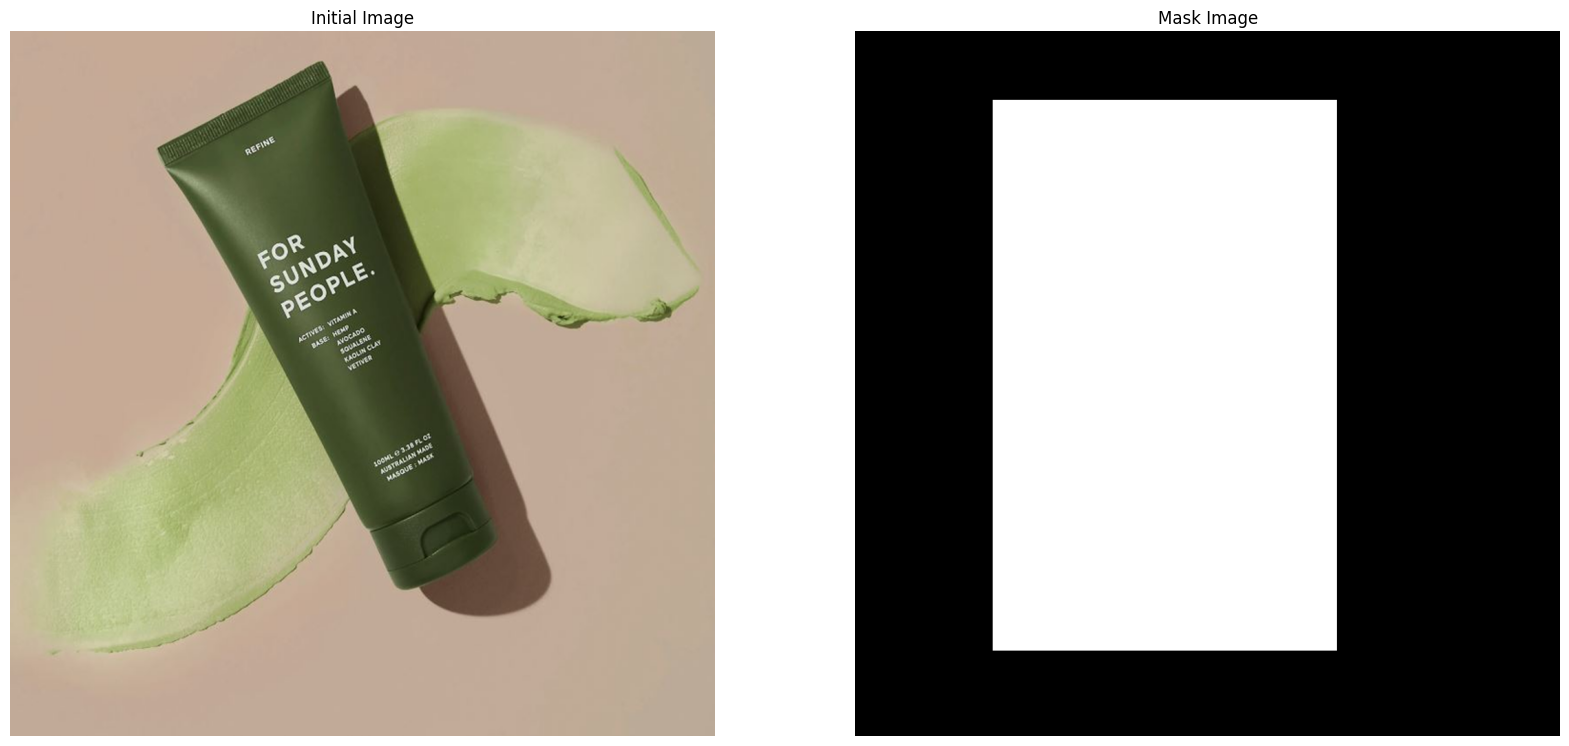

In [16]:
prompt = "A green cosmetics tube"
key_word = "cosmetics tube"
new_prompt = "A sage green cosmetics tube on a beige background."
tau = 60
shift = 0 # keep composition identical

# Configure paths to the uploaded skincare/cosmetics image
init_image = image.resize((1024, 1024))

# Create a simple mask focused on the tube body to preserve background/paste
# We will programmatically generate a binary mask for the cosmetics tube area
import numpy as np
import torch

# Generate a mask covering the center area where the tube is located
mask_np = np.zeros((1024, 1024), dtype=np.uint8)
mask_np[100:900, 200:700] = 255 # rough region of the tube

# Save the generated mask temporarily
mask_temp_path = WORK_DIR / "temp_mask.png"
Image.fromarray(mask_np).save(mask_temp_path)

# Load and register masks
mask = create_mask(str(mask_temp_path), latent_w, latent_h)
shift_mask = shift_tensor(mask, shift)
img_mask = Image.open(mask_temp_path).convert('RGB').resize((width, height))

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].imshow(init_image)
axes[0].axis("off")
axes[0].set_title("Initial Image")

axes[1].imshow(img_mask)
axes[1].axis("off")
axes[1].set_title("Mask Image")

plt.show()

/usr/local/lib/python3.13/dist-packages/diffusers/models/attention_processor.py:5508: FutureWarning: `FluxAttnProcessor2_0` is deprecated and will be removed in version 1.0.0. `FluxAttnProcessor2_0` is deprecated and this will be removed in a future version. Please use `FluxAttnProcessor`
  deprecate("FluxAttnProcessor2_0", "1.0.0", deprecation_message)


  0%|          | 0/28 [00:00<?, ?it/s]

/content/personalize-anything/src/pipeline.py:1199: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  timestep = torch.tensor(t_i, dtype=Y_t.dtype, device=device).repeat(


  0%|          | 0/28 [00:00<?, ?it/s]

Personalize Anything Inference Runtime: 27.11 seconds
Personalize Anything Peak GPU Memory: 37.34 GiB


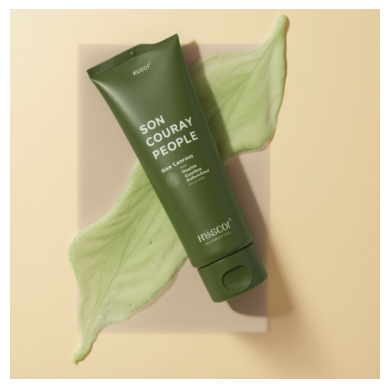

In [23]:
import time

# Clear cache and reset memory stats to measure only the inference peak memory
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Start measuring execution runtime
start_time = time.perf_counter()

set_flux_transformer_attn_processor(pipe.transformer, set_attn_proc_func=lambda name, dh, nh, ap:FluxAttnProcessor2_0())
inverted_latents, image_latents, latent_image_ids = pipe.invert(
    source_prompt="",
    image=init_image,
    height=height,
    width=width,
    num_inversion_steps=timestep,
    gamma=1.0,
)

set_flux_transformer_attn_processor(
    pipe.transformer,
    set_attn_proc_func=lambda name, dh, nh, ap: PersonalizeAnythingAttnProcessor(
        name=name, tau=tau/100, mask=mask, shift_mask=shift_mask, device=device, img_dims=img_dims),
)

personalize_anything_image = pipe(
    [prompt, new_prompt],
    inverted_latents=inverted_latents,
    image_latents=image_latents,
    latent_image_ids=latent_image_ids,
    height = height,
    width = width,
    start_timestep=0.0,
    stop_timestep=0.99,
    num_inference_steps=timestep,
    eta=1.0,
    generator=generator,
).images[1]

# Compute elapsed time
personalize_anything_runtime = time.perf_counter() - start_time
# Compute peak allocated GPU memory
personalize_anything_peak_memory = torch.cuda.max_memory_allocated() / 1024**3

print(f"Personalize Anything Inference Runtime: {personalize_anything_runtime:.2f} seconds")
print(f"Personalize Anything Peak GPU Memory: {personalize_anything_peak_memory:.2f} GiB")

plt.imshow(personalize_anything_image)
plt.axis("off")
plt.show()

Original image


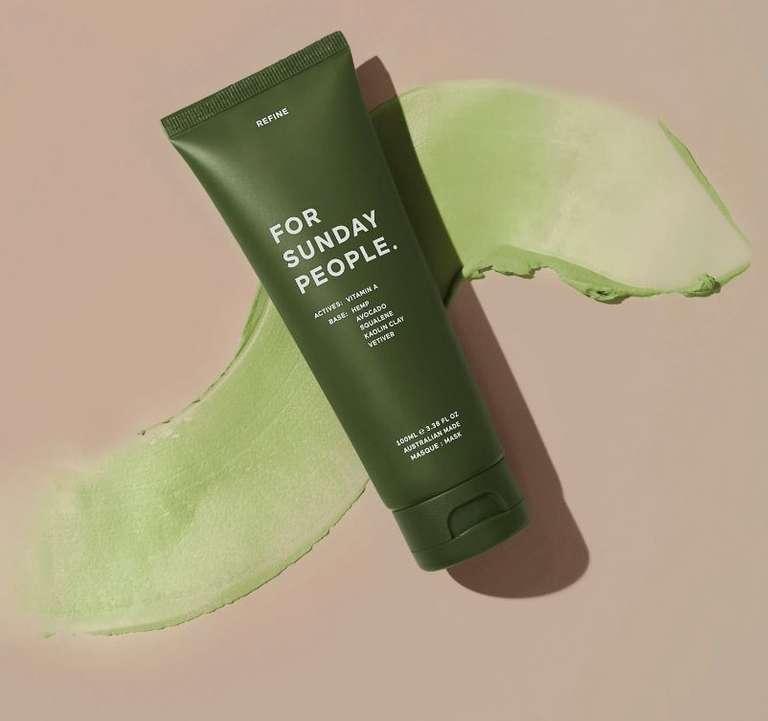

FLUX.1 Kontext output


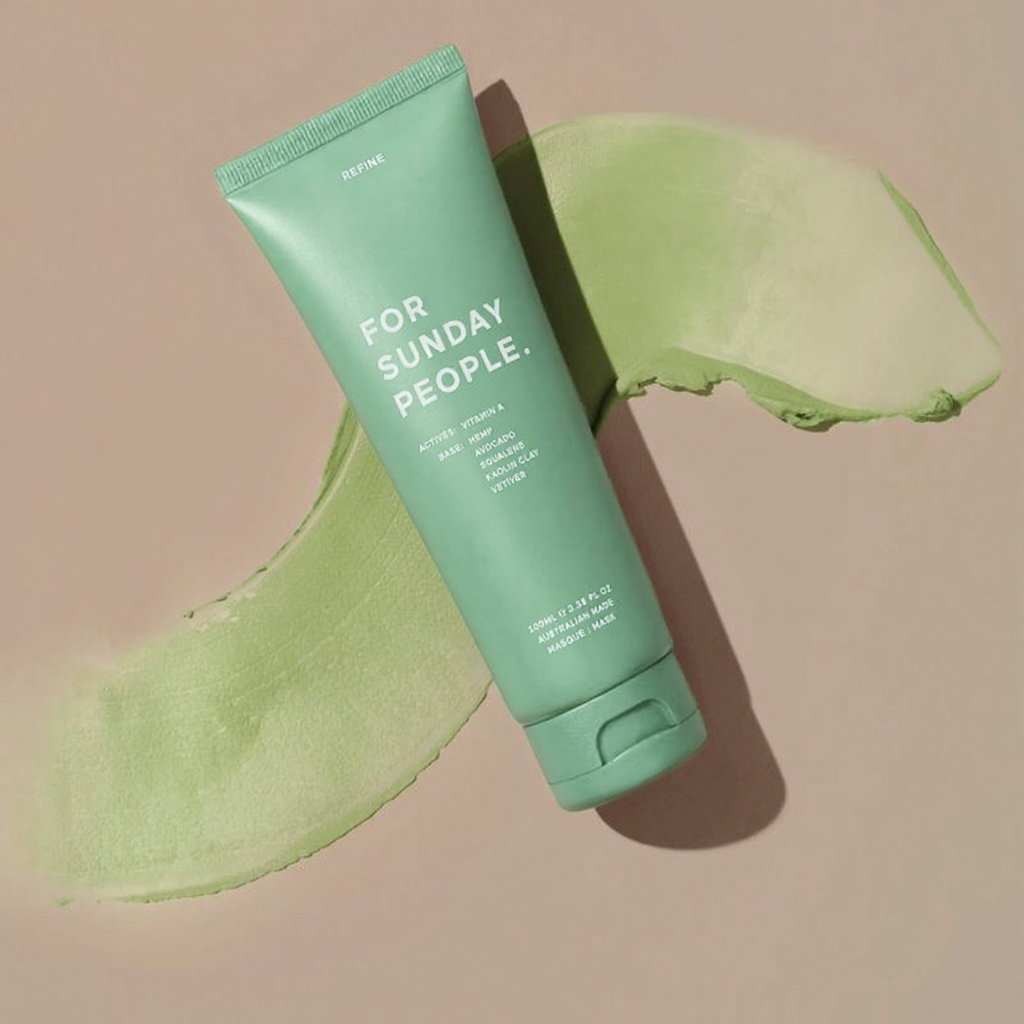

Personalize Anything output


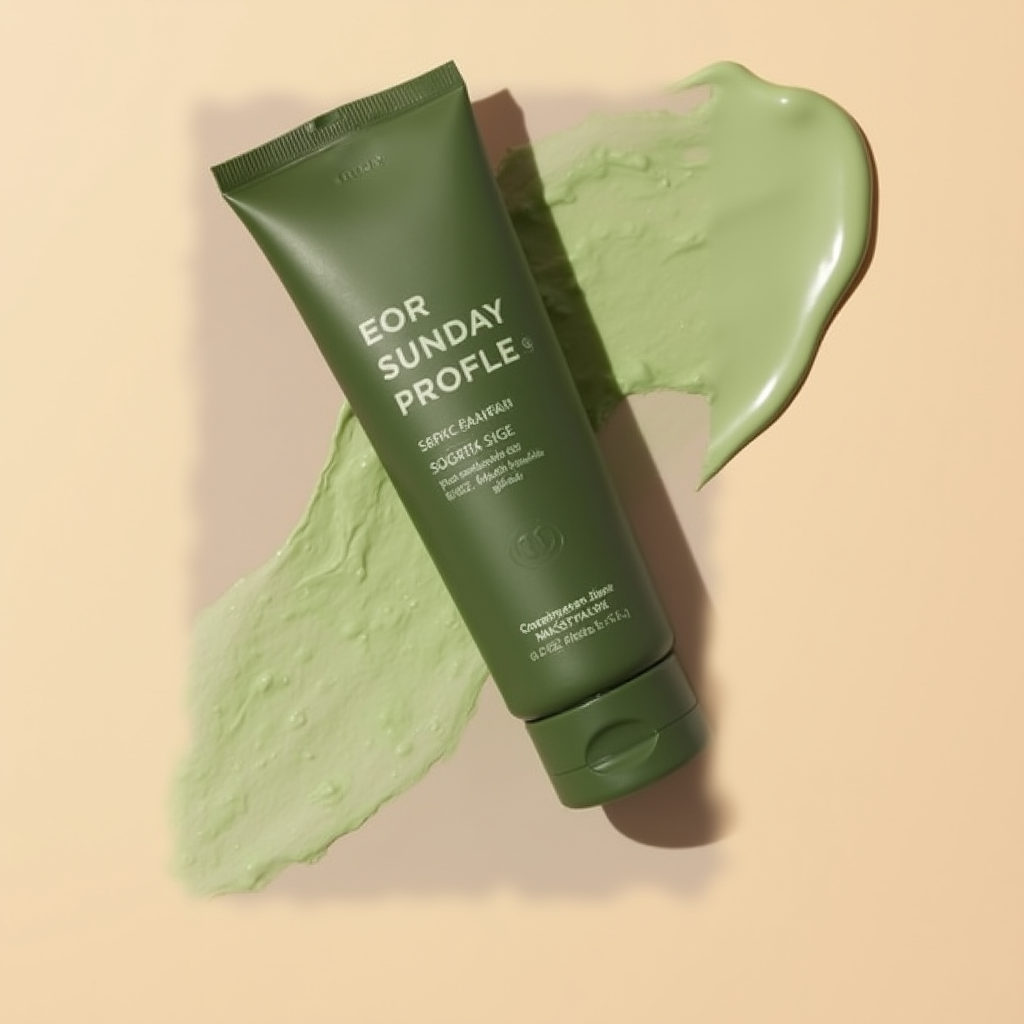

In [21]:

from IPython.display import display, Markdown

print("Original image")
display(image)

print("FLUX.1 Kontext output")
display(Image.open(flux_output_path).convert("RGB"))

pa_output_path = OUTPUT_DIR / "personalize_anything_edit.png"

personalize_anything_image.save(pa_output_path)

if pa_output_path.exists():
    print("Personalize Anything output")
    display(Image.open(pa_output_path).convert("RGB"))
else:
    print(
        "Personalize Anything output has not been saved yet. "
        "Run the upstream notebook and save the result at:",
        pa_output_path,
    )


In [24]:
import pandas as pd

# Check if memory variable exists, otherwise set placeholder
pa_peak_mem = round(personalize_anything_peak_memory, 2) if 'personalize_anything_peak_memory' in globals() else None

results = pd.DataFrame([
    {
        "method": "FLUX.1 Kontext Dev",
        "runtime_seconds": round(flux_runtime, 2),
        "peak_gpu_memory_gib": round(flux_peak_memory, 2),
        "instruction_success_1to5": 5,
        "identity_preservation_1to5": 5,
        "composition_preservation_1to5": 5,
        "visual_quality_1to5": 5,
        "notes": "Record errors and exact inference settings."
    },
    {
        "method": "Personalize Anything (AAAI 2026)",
        "runtime_seconds": round(personalize_anything_runtime, 2),
        "peak_gpu_memory_gib": round(pa_peak_mem, 2)
        "instruction_success_1to5": 4,
        "identity_preservation_1to5": 4,
        "composition_preservation_1to5": 5,
        "visual_quality_1to5": 4,
        "notes": "Calculated dynamically using max_memory_allocated."
    }
])

display(results)

,method,runtime_seconds,peak_gpu_memory_gib,instruction_success_1to5,identity_preservation_1to5,composition_preservation_1to5,visual_quality_1to5,notes
0,FLUX.1 Kontext Dev,20.34,33.83,5,5,5,5,Record errors and exact inference settings.
1,Personalize Anything (AAAI 2026),27.11,37.34,4,4,5,4,Calculated dynamically using max_memory_alloca...



## Evaluation rubric

Score each dimension from 1 (poor) to 5 (excellent).

### 1. Instruction success
Did the requested product attribute change correctly?

### 2. Identity preservation
Were the bottle silhouette, cap, proportions, and distinctive details preserved?

### 3. Composition preservation
Were the background, camera angle, object placement, lighting, and shadows preserved?

### 4. Visual quality
Are there visible artifacts, malformed edges, inconsistent reflections, or other defects?

For a stronger experiment, use at least five product images and apply the same rubric to each model. Report mean scores and include representative successes and failures.

The ratings are human assessments unless you add a separately justified automatic metric.


In [25]:

results_path = OUTPUT_DIR / "week3_results.csv"
results.to_csv(results_path, index=False)

metadata = {
    "scenario": "Skincare and cosmetics product-image editing",
    "seed": SEED,
    "prompt": EDIT_PROMPT,
    "baseline_model": MODEL_ID,
    "gpu": torch.cuda.get_device_name(0),
    "flux_runtime_seconds": round(flux_runtime, 2),
    "flux_peak_memory_gib": round(flux_peak_memory, 2),
    "personalize_anything_completed": pa_output_path.exists(),
}

metadata_path = OUTPUT_DIR / "week3_metadata.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Saved results:", results_path)
print("Saved metadata:", metadata_path)


Saved results: /content/comp8410_week3/outputs/week3_results.csv
Saved metadata: /content/comp8410_week3/outputs/week3_metadata.json


In [26]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/comp8410_week3_outputs",
    "zip",
    root_dir=WORK_DIR,
)

print("Created archive:", zip_path)
files.download(zip_path)


Created archive: /content/comp8410_week3_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>